In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

In [2]:
# Memuat dataset Breast Cancer Wisconsin
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

# Nama kelas pada dataset: malignant dan benign
class_names = data.target_names

print("Ukuran dataset:", X.shape)
print("\nJumlah data setiap kelas:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

display(X.head())

Ukuran dataset: (569, 30)

Jumlah data setiap kelas:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Jumlah data keseluruhan : {len(X)}")
print(f"Data training (70%)     : {len(X_train)}")
print(f"Data testing (30%)      : {len(X_test)}")

Jumlah data keseluruhan : 569
Data training (70%)     : 398
Data testing (30%)      : 171


In [4]:
# Model 1: Logistic Regression
# StandardScaler digunakan karena Logistic Regression sensitif terhadap skala fitur.
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
)

# Model 2: Random Forest
# Random Forest merupakan model berbasis kumpulan decision tree.
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE
)

# Melatih kedua model menggunakan data training
model_lr.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

print("Logistic Regression dan Random Forest berhasil dilatih.")

Logistic Regression dan Random Forest berhasil dilatih.


In [5]:
y_pred_lr = model_lr.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

print("Prediksi kedua model berhasil dilakukan.")

Prediksi kedua model berhasil dilakukan.


In [6]:
# Menghitung metrik evaluasi untuk masing-masing model
model_names = ["Logistic Regression", "Random Forest"]
predictions = [y_pred_lr, y_pred_rf]

evaluation = []

for name, y_pred in zip(model_names, predictions):
    evaluation.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results = pd.DataFrame(evaluation)
display(results.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}"
}))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9883,0.9883,0.9883,0.9883
1,Random Forest,0.9357,0.9355,0.9357,0.9356


In [7]:
print("=== Logistic Regression ===")
print(classification_report(
    y_test, y_pred_lr, target_names=class_names, zero_division=0
))

print("=== Random Forest ===")
print(classification_report(
    y_test, y_pred_rf, target_names=class_names, zero_division=0
))

=== Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

=== Random Forest ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



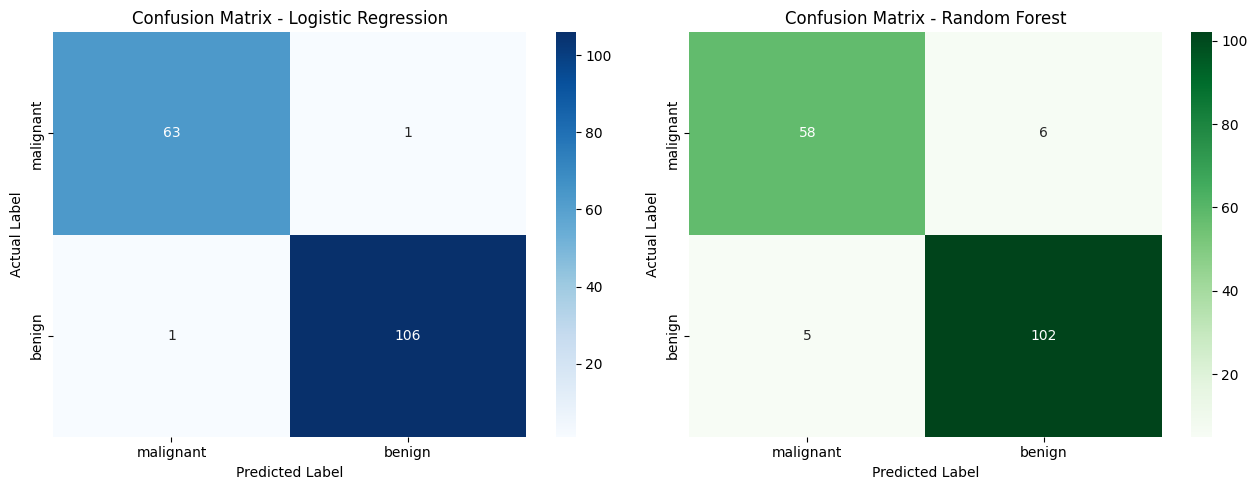

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm_lr, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names, ax=axes[0]
)
axes[0].set_title("Confusion Matrix - Logistic Regression")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Greens",
    xticklabels=class_names, yticklabels=class_names, ax=axes[1]
)
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

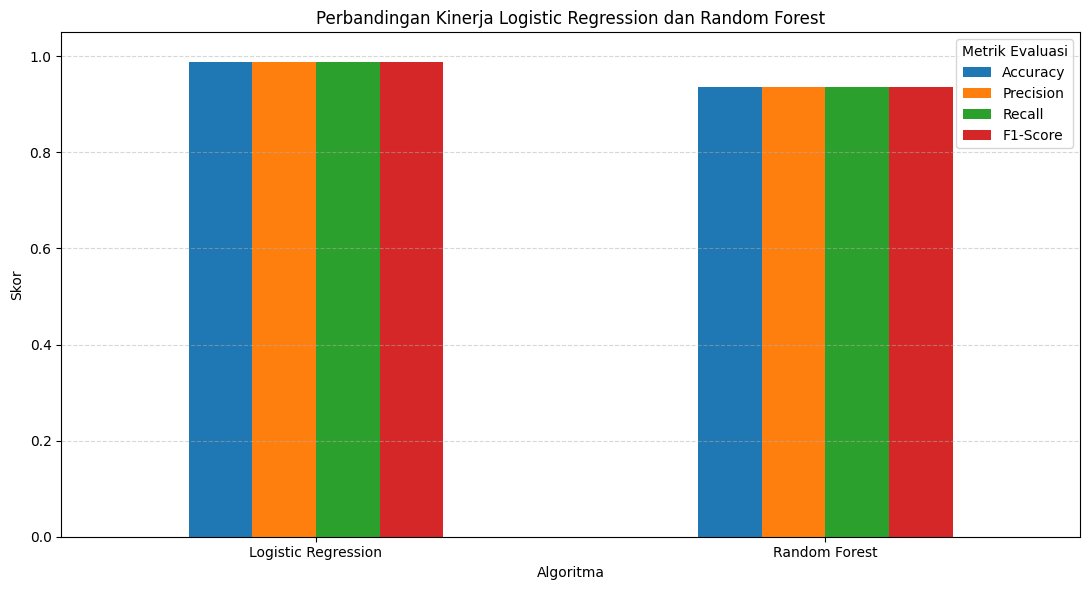

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

plot_data = results.set_index("Model")[metrics]

ax = plot_data.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05), rot=0)
ax.set_title("Perbandingan Kinerja Logistic Regression dan Random Forest")
ax.set_xlabel("Algoritma")
ax.set_ylabel("Skor")
ax.legend(title="Metrik Evaluasi")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("evaluation_results.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# Menentukan model berdasarkan F1-score tertinggi.
# Jika nilainya sama, hasil tetap ditampilkan sebagai seri pada metrik F1-score.
best_index = results["F1-Score"].idxmax()
best_model = results.loc[best_index, "Model"]
best_f1 = results.loc[best_index, "F1-Score"]

print("Model dengan F1-Score tertinggi:", best_model)
print(f"Nilai F1-Score: {best_f1:.4f}")

print("\nRingkasan hasil evaluasi:")
display(results)

Model dengan F1-Score tertinggi: Logistic Regression
Nilai F1-Score: 0.9883

Ringkasan hasil evaluasi:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.988304,0.988304,0.988304,0.988304
1,Random Forest,0.935673,0.935533,0.935673,0.935569


In [11]:
# Dua gambar berikut dibuat pada bagian visualisasi:
# 1. confusion_matrix.png
# 2. evaluation_results.png

import os
print("File hasil yang tersedia:")
for filename in ["confusion_matrix.png", "evaluation_results.png"]:
    print(f"{filename}: {'tersedia' if os.path.exists(filename) else 'belum dibuat'}")

File hasil yang tersedia:
confusion_matrix.png: tersedia
evaluation_results.png: tersedia


In [12]:
from google.colab import files

files.download("confusion_matrix.png")
files.download("evaluation_results.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>